# TravelData case study python file

NB: this Python notebook draws from a .csv copy of the traveldata.xslx file's 'data' sheet

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [58]:
pwd

'C:\\Users\\lucas\\OneDrive\\CU Denver\\BANA 6610'

In [59]:
df = pd.read_csv('TravelData.csv')

### Data Preprocessing & Quality Check

#### Find and deal with missing values

In [60]:
df.head()

,clientid,bkgref,Trip ID,destination,destinationcountry,destinationcountry2,category,date_of_trip_from,date_of_trip_to,year,month,bkgsource,landsalecost_total,anticipatedcommission_total,groupsize
0,138,B12-28876,150,Alaska Fishing,Alaska,Alaska,FW,7/14/2012,7/22/2012,2012,7,Company referral,4550.0,455.00,1
1,138,B15-39172,238,H2O Bahamas,Bahamas,Bahamas,SW,10/30/2015,11/3/2015,2015,10,Repeat Client,7260.0,1012.52,4
2,138,B18-49058,211,Deep Water Cay,Bahamas,Bahamas,SW,2/15/2019,2/19/2019,2019,2,Repeat Client,14598.5,2300.00,4
3,138,B19-51320,230,Mangrove Cay,Bahamas,Bahamas,SW,11/3/2019,11/7/2019,2019,11,Repeat Client,14280.0,2856.00,4
4,138,B19-52213,215,The Delphi Club,Bahamas,Bahamas,SW,2/13/2020,2/18/2020,2020,2,Repeat Client,7615.0,914.40,2


In [61]:
df.describe()

,Trip ID,year,month,landsalecost_total,anticipatedcommission_total,groupsize
count,16681.000000,16681.000000,16681.000000,1.668100e+04,16681.000000,16681.000000
mean,499.595588,2016.672622,6.053534,1.234072e+04,1721.492028,1.970146
std,265.991108,3.156520,3.084707,4.224807e+04,2519.972780,1.764510
min,101.000000,2010.000000,1.000000,0.000000e+00,-400.000000,1.000000
25%,241.000000,2014.000000,4.000000,4.050000e+03,590.000000,1.000000
50%,380.000000,2017.000000,6.000000,7.190000e+03,1072.000000,2.000000
75%,806.000000,2019.000000,8.000000,1.366600e+04,2000.000000,2.000000
max,900.000000,2022.000000,12.000000,4.900000e+06,63000.000000,37.000000


In [62]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16681 entries, 0 to 16680
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   clientid                     16681 non-null  str    
 1   bkgref                       16681 non-null  str    
 2   Trip ID                      16681 non-null  int64  
 3   destination                  16681 non-null  str    
 4   destinationcountry           16676 non-null  str    
 5   destinationcountry2          16676 non-null  str    
 6   category                     16681 non-null  str    
 7   date_of_trip_from            16681 non-null  str    
 8   date_of_trip_to              16681 non-null  str    
 9   year                         16681 non-null  int64  
 10  month                        16681 non-null  int64  
 11  bkgsource                    16656 non-null  str    
 12  landsalecost_total           16681 non-null  float64
 13  anticipatedcommission_total

In [63]:
df['bkgsource'].value_counts()

bkgsource
Repeat Client        9214
UK                   2126
Company referral     1950
Friend               1872
Agent/Outfitter       729
Web/Internet/Mail     637
Organizations          50
Frontiers, Ltd.        37
Magazine               23
Trade Shows            13
Internet Chat           5
Name: count, dtype: int64

In [64]:
df[(df['destinationcountry'].isna()) | (df['destinationcountry2'].isna())]

,clientid,bkgref,Trip ID,destination,destinationcountry,destinationcountry2,category,date_of_trip_from,date_of_trip_to,year,month,bkgsource,landsalecost_total,anticipatedcommission_total,groupsize
1060,08-45298,B16-41008,900,Air-FIT,NaN,NaN,FIT,6/12/2016,6/21/2016,2016,6,Repeat Client,0.0,0.0,2
3628,11-52647,B16-40506,900,Air-FIT,NaN,NaN,FIT,9/5/2016,9/19/2016,2016,9,Repeat Client,0.0,0.0,2
4906,13-56149,B15-40058,900,Air-FIT,NaN,NaN,FIT,1/9/2016,1/16/2016,2016,1,Repeat Client,0.0,0.0,1
8062,17-62585,B19-50120,900,Air-FIT,NaN,NaN,FIT,6/11/2019,6/25/2019,2019,6,Repeat Client,0.0,0.0,1
10021,19-65503,B19-49397,900,Air-FIT,NaN,NaN,FIT,4/25/2019,4/29/2019,2019,4,Friend,0.0,0.0,1


In [65]:
(df['destination']=='Air-FIT').sum()

np.int64(5)

In [66]:
df = df.drop(index=[1060,3628,4906,8062,10021]) # drop rows with NaN for destinationcountry and destinationcountry2

In [67]:
df[(df['destinationcountry'].isna()) | (df['destinationcountry2'].isna())]

,clientid,bkgref,Trip ID,destination,destinationcountry,destinationcountry2,category,date_of_trip_from,date_of_trip_to,year,month,bkgsource,landsalecost_total,anticipatedcommission_total,groupsize


In [68]:
df['bkgsource'].value_counts(normalize=True)

bkgsource
Repeat Client        0.553120
UK                   0.127680
Company referral     0.117110
Friend               0.112366
Agent/Outfitter      0.043781
Web/Internet/Mail    0.038256
Organizations        0.003003
Frontiers, Ltd.      0.002222
Magazine             0.001381
Trade Shows          0.000781
Internet Chat        0.000300
Name: proportion, dtype: float64

In [69]:
df[df['bkgsource'].isna()]

,clientid,bkgref,Trip ID,destination,destinationcountry,destinationcountry2,category,date_of_trip_from,date_of_trip_to,year,month,bkgsource,landsalecost_total,anticipatedcommission_total,groupsize
248,02116MIL1,B10-23219,851,Turkey & Middle East,Turkey,Turkey,FIT,4/16/2010,4/25/2010,2010,4,NaN,1574.0,0.00,1
1084,08-45372,B10-23162,830,France,France,France,FIT,7/5/2010,7/18/2010,2010,7,NaN,9465.0,900.00,3
1099,08-45428,B10-23225,271,Los Roques,Venezuela,Venezuela,SW,5/10/2010,5/14/2010,2010,5,NaN,2545.0,636.25,1
1201,08-45783,B10-23103,808,Europe FIT,Europe,Europe,FIT,6/23/2010,7/8/2010,2010,6,NaN,36677.8,2357.00,5
1238,08-46434,B10-23132,800,US Fit,US,US,FIT,8/7/2010,8/14/2010,2010,8,NaN,4100.0,410.00,2
1504,09-47117,B10-23153,206,Boca Paila,Mexico,Mexico,SW,3/6/2011,3/13/2011,2011,3,NaN,6200.0,563.64,2
1632,09-47493,B10-23157,806,Caribbean,Caribbean,Caribbean,FIT,12/27/2010,1/4/2011,2010,12,NaN,8800.0,1200.00,6
2038,10019MAU1,B10-23161,831,Italy,Italy,Italy,FIT,10/23/2010,11/4/2010,2010,10,NaN,9718.0,900.00,2
2118,10022STR02,B10-23220,339,Argentina Fishing-Rio Grande,Argentina,Argentina,FO,1/14/2011,1/30/2011,2011,1,NaN,9870.0,1932.50,1
2504,10-48849,B10-23146,327,New Zealand Fishing,New Zealand,New Zealand,FO,3/26/2011,4/7/2011,2011,3,NaN,20015.0,2044.00,2


In [70]:
df['bkgsource'] = df['bkgsource'].fillna('Unknown')

In [71]:
df.info()

<class 'pandas.DataFrame'>
Index: 16676 entries, 0 to 16680
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   clientid                     16676 non-null  str    
 1   bkgref                       16676 non-null  str    
 2   Trip ID                      16676 non-null  int64  
 3   destination                  16676 non-null  str    
 4   destinationcountry           16676 non-null  str    
 5   destinationcountry2          16676 non-null  str    
 6   category                     16676 non-null  str    
 7   date_of_trip_from            16676 non-null  str    
 8   date_of_trip_to              16676 non-null  str    
 9   year                         16676 non-null  int64  
 10  month                        16676 non-null  int64  
 11  bkgsource                    16676 non-null  str    
 12  landsalecost_total           16676 non-null  float64
 13  anticipatedcommission_total  166

#### Look for inconsistencies and unusual values and deal with them

In [72]:
df.describe()

,Trip ID,year,month,landsalecost_total,anticipatedcommission_total,groupsize
count,16676.000000,16676.000000,16676.000000,1.667600e+04,16676.000000,16676.000000
mean,499.475534,2016.672463,6.053790,1.234442e+04,1722.008187,1.970317
std,265.940589,3.156878,3.084796,4.225386e+04,2520.174211,1.764727
min,101.000000,2010.000000,1.000000,0.000000e+00,-400.000000,1.000000
25%,241.000000,2014.000000,4.000000,4.050000e+03,590.000000,1.000000
50%,380.000000,2017.000000,6.000000,7.197500e+03,1073.535000,2.000000
75%,806.000000,2019.000000,8.000000,1.367045e+04,2000.000000,2.000000
max,890.000000,2022.000000,12.000000,4.900000e+06,63000.000000,37.000000


(array([1.5782e+04, 7.0100e+02, 9.7000e+01, 5.2000e+01, 2.5000e+01,
        8.0000e+00, 4.0000e+00, 1.0000e+00, 4.0000e+00, 2.0000e+00]),
 array([ 1. ,  4.6,  8.2, 11.8, 15.4, 19. , 22.6, 26.2, 29.8, 33.4, 37. ]),
 <BarContainer object of 10 artists>)

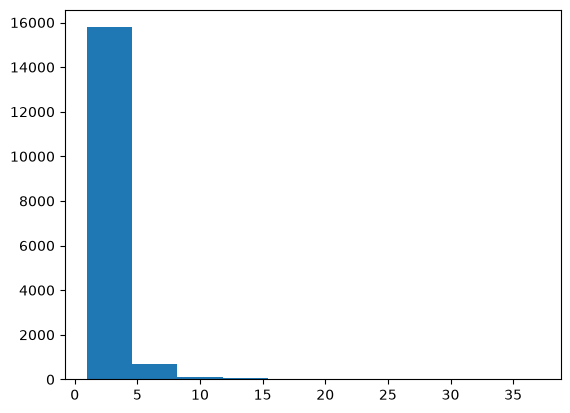

In [73]:
plt.hist(df['groupsize']) # IQR of groupsize is 1, so any group size over 2 + 3*1 = 5 is a strong outlier - but check that this makes sense via histogram

In [74]:
df[df['groupsize']>5]

,clientid,bkgref,Trip ID,destination,destinationcountry,destinationcountry2,category,date_of_trip_from,date_of_trip_to,year,month,bkgsource,landsalecost_total,anticipatedcommission_total,groupsize
11,100651,B10-24530,806,Caribbean,Caribbean,Caribbean,FIT,12/26/2010,1/1/2011,2010,12,Company referral,15576.0,1557.0,6
12,100651,B10-24665,806,Caribbean,Caribbean,Caribbean,FIT,3/20/2011,3/27/2011,2011,3,Company referral,11325.0,1130.0,6
14,100651,B11-27139,806,Caribbean,Caribbean,Caribbean,FIT,12/26/2011,1/1/2012,2011,12,Company referral,17310.0,1720.0,6
16,100651,B12-28598,806,Caribbean,Caribbean,Caribbean,FIT,12/26/2012,1/2/2013,2012,12,Company referral,13300.0,1162.0,6
18,100651,B13-32422,808,Europe FIT,Europe,Europe,FIT,8/12/2013,8/20/2013,2013,8,Repeat Client,29997.0,3136.0,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16378,MEXICNEL3,B18-46943,550,Denmark Pheasants,Denmark,Denmark,WS,10/21/2018,10/26/2018,2018,10,Repeat Client,351175.0,29600.0,17
16425,NW 11STE1,B21-54247,227,Seychelles - Misc,Seychelles,Seychelles,SW,12/11/2021,12/27/2021,2021,12,UK,117890.0,22515.0,6
16493,SG4 8BLY1,B16-40182,651,S. Africa FIT,S. Africa,S. Africa,AFR,2/29/2016,3/7/2016,2016,2,UK,15842.0,2480.0,8
16496,SG4 8BLY1,B17-43475,800,US FIT,US,US,FIT,4/9/2017,4/13/2017,2017,4,UK,11907.0,525.0,7


In [75]:
df[df['groupsize']>5]['groupsize'].value_counts().sort_index()

groupsize
6     237
7      79
8      81
9      32
10     46
11     19
12     29
13      5
14     14
15      4
16     11
17      9
18      5
19      2
20      3
21      2
22      1
23      1
24      2
25      1
28      1
30      2
32      1
33      1
37      2
Name: count, dtype: int64

In [76]:
df[df['groupsize']>18]['groupsize'].count()

np.int64(19)

In [77]:
df[df['groupsize']==10]

,clientid,bkgref,Trip ID,destination,destinationcountry,destinationcountry2,category,date_of_trip_from,date_of_trip_to,year,month,bkgsource,landsalecost_total,anticipatedcommission_total,groupsize
281,02332RIE1,B10-22206,808,Europe FIT,Europe,Europe,FIT,6/23/2010,6/28/2010,2010,6,Company referral,19106.40,2246.50,10
399,03301HIR1,B14-36760,810,Asia FIT,Asia,Asia,FIT,12/14/2014,12/16/2014,2014,12,Repeat Client,5550.00,950.00,10
1136,08-45556,B21-54705,800,US FIT,US,US,FIT,8/11/2021,8/15/2021,2021,8,Repeat Client,22800.00,2280.00,10
1182,08-45775,B14-35403,806,Caribbean,Caribbean,Caribbean,FIT,2/13/2015,2/22/2015,2015,2,Repeat Client,18720.00,1870.00,10
1509,09-47117,B11-25784,206,Boca Paila,Mexico,Mexico,SW,3/25/2012,4/1/2012,2012,3,Agent/Outfitter,26550.00,2413.56,10
1523,09-47117,B17-44846,233,Bahamas Misc Saltwater,Bahamas,Bahamas,SW,2/18/2018,2/25/2018,2018,2,Agent/Outfitter,41756.00,6022.50,10
1524,09-47117,B17-44849,233,Bahamas Misc Saltwater,Bahamas,Bahamas,SW,3/18/2018,3/25/2018,2018,3,Agent/Outfitter,45864.00,6615.00,10
1525,09-47117,B18-46867,209,Yucatan Fishing Misc,Mexico,Mexico,SW,7/19/2018,7/23/2018,2018,7,Agent/Outfitter,19755.00,1712.10,10
1527,09-47117,B18-47539,209,Yucatan Fishing Misc,Mexico,Mexico,SW,4/27/2019,5/4/2019,2019,4,Agent/Outfitter,26910.00,2691.00,10
1529,09-47117,B19-50913,224,Turneffe Flats Lodge,Belize,Belize,SW,3/14/2020,3/21/2020,2020,3,Agent/Outfitter,41545.00,7702.00,10


In [78]:
df[df['groupsize']==20]

,clientid,bkgref,Trip ID,destination,destinationcountry,destinationcountry2,category,date_of_trip_from,date_of_trip_to,year,month,bkgsource,landsalecost_total,anticipatedcommission_total,groupsize
1513,09-47117,B14-35786,210,Grand Slam Lodge,Mexico,Mexico,SW,3/14/2015,3/21/2015,2015,3,Agent/Outfitter,58270.1,5826.96,20
9111,18-64803,B18-47443,851,Turkey/MiddleEast/Morocco,Turkey,Turkey,FIT,8/3/2019,8/10/2019,2019,8,UK,30840.3,680.00,20
16159,FINLAMOI5,B12-30775,380,Ponoi,Russia,Russia,FO,8/3/2013,8/10/2013,2013,8,UK,84000.0,12300.00,20


In [79]:
df[df['groupsize']==1].describe()

,Trip ID,year,month,landsalecost_total,anticipatedcommission_total,groupsize
count,7688.000000,7688.000000,7688.000000,7688.000000,7688.000000,7688.0
mean,383.578434,2016.754032,5.771202,6911.706623,1025.383748,1.0
std,207.761128,3.222382,2.973946,11693.102141,1347.003161,0.0
min,101.000000,2010.000000,1.000000,0.000000,-400.000000,1.0
25%,224.000000,2014.000000,3.000000,3360.000000,535.375000,1.0
50%,352.000000,2017.000000,6.000000,5245.000000,846.300000,1.0
75%,516.000000,2019.000000,8.000000,7996.250000,1290.000000,1.0
max,890.000000,2022.000000,12.000000,408064.000000,47259.000000,1.0


In [80]:
df[df['groupsize']==2].describe()

,Trip ID,year,month,landsalecost_total,anticipatedcommission_total,groupsize
count,6614.000000,6614.000000,6614.000000,6.614000e+03,6614.000000,6614.0
mean,583.905806,2016.617629,6.150136,1.364271e+04,1885.077368,2.0
std,273.216032,3.092553,3.166385,6.181391e+04,2111.592236,0.0
min,101.000000,2010.000000,1.000000,0.000000e+00,0.000000,2.0
25%,312.000000,2014.000000,3.000000,5.000000e+03,630.000000,2.0
50%,800.000000,2017.000000,6.000000,9.377500e+03,1380.000000,2.0
75%,812.000000,2019.000000,9.000000,1.625700e+04,2441.500000,2.0
max,853.000000,2022.000000,12.000000,4.900000e+06,44891.000000,2.0


In [81]:
df[df['groupsize']>18].describe()

,Trip ID,year,month,landsalecost_total,anticipatedcommission_total,groupsize
count,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000
mean,550.684211,2015.210526,6.684211,88091.442105,12275.567895,25.526316
std,249.628180,3.137213,2.334586,61806.411434,9695.301294,6.003410
min,150.000000,2011.000000,1.000000,10930.200000,680.000000,19.000000
25%,380.000000,2012.000000,6.000000,40779.150000,4449.480000,20.500000
50%,504.000000,2016.000000,7.000000,84000.000000,12150.100000,24.000000
75%,802.000000,2018.000000,8.000000,115713.500000,14640.000000,30.000000
max,851.000000,2019.000000,10.000000,265096.000000,31474.000000,37.000000


In [82]:
df[df['groupsize']<=18].describe()

,Trip ID,year,month,landsalecost_total,anticipatedcommission_total,groupsize
count,16657.000000,16657.000000,16657.000000,1.665700e+04,16657.000000,16657.000000
mean,499.417122,2016.674131,6.053071,1.225802e+04,1709.970147,1.943447
std,265.960029,3.156607,3.085527,4.215145e+04,2475.831705,1.563703
min,101.000000,2010.000000,1.000000,0.000000e+00,-400.000000,1.000000
25%,241.000000,2014.000000,4.000000,4.050000e+03,590.000000,1.000000
50%,380.000000,2017.000000,6.000000,7.190000e+03,1071.000000,2.000000
75%,806.000000,2019.000000,8.000000,1.362410e+04,2000.000000,2.000000
max,890.000000,2022.000000,12.000000,4.900000e+06,63000.000000,18.000000


In [83]:
df = df[df['groupsize']<=18]

In [84]:
df.describe()

,Trip ID,year,month,landsalecost_total,anticipatedcommission_total,groupsize
count,16657.000000,16657.000000,16657.000000,1.665700e+04,16657.000000,16657.000000
mean,499.417122,2016.674131,6.053071,1.225802e+04,1709.970147,1.943447
std,265.960029,3.156607,3.085527,4.215145e+04,2475.831705,1.563703
min,101.000000,2010.000000,1.000000,0.000000e+00,-400.000000,1.000000
25%,241.000000,2014.000000,4.000000,4.050000e+03,590.000000,1.000000
50%,380.000000,2017.000000,6.000000,7.190000e+03,1071.000000,2.000000
75%,806.000000,2019.000000,8.000000,1.362410e+04,2000.000000,2.000000
max,890.000000,2022.000000,12.000000,4.900000e+06,63000.000000,18.000000


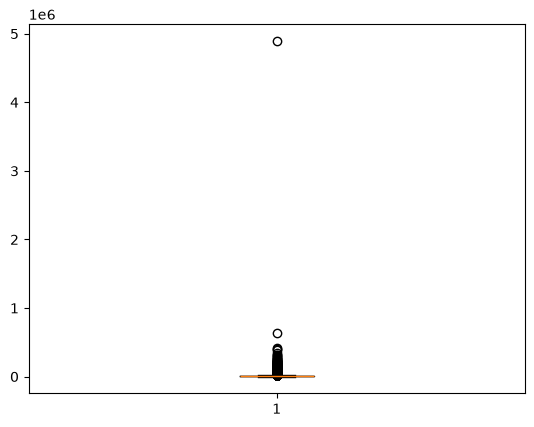

In [87]:
plt.boxplot(df['landsalecost_total'])
plt.show()

In [90]:
df[df['landsalecost_total']>500000]

,clientid,bkgref,Trip ID,destination,destinationcountry,destinationcountry2,category,date_of_trip_from,date_of_trip_to,year,month,bkgsource,landsalecost_total,anticipatedcommission_total,groupsize
4308,12-55017,B20-54006,806,Caribbean / Mexico FIT,Caribbean,Caribbean,FIT,12/18/2020,1/29/2021,2020,12,Repeat Client,630000.0,63000.0,14
9120,18-64825,B18-47473,842,Scandinavia,Scandinavia,Scandinavia,FIT,9/22/2018,9/30/2018,2018,9,Repeat Client,4900000.0,427.4,2


In [91]:
df = df[df['landsalecost_total']<=1000000]

In [92]:
df.describe()

,Trip ID,year,month,landsalecost_total,anticipatedcommission_total,groupsize
count,16656.000000,16656.000000,16656.000000,16656.000000,16656.000000,16656.000000
mean,499.396554,2016.674051,6.052894,11964.563303,1710.047150,1.943444
std,265.954765,3.156685,3.085535,18502.975226,2475.886084,1.563750
min,101.000000,2010.000000,1.000000,0.000000,-400.000000,1.000000
25%,241.000000,2014.000000,4.000000,4050.000000,590.000000,1.000000
50%,380.000000,2017.000000,6.000000,7187.800000,1071.000000,2.000000
75%,806.000000,2019.000000,8.000000,13621.025000,2000.000000,2.000000
max,890.000000,2022.000000,12.000000,630000.000000,63000.000000,18.000000


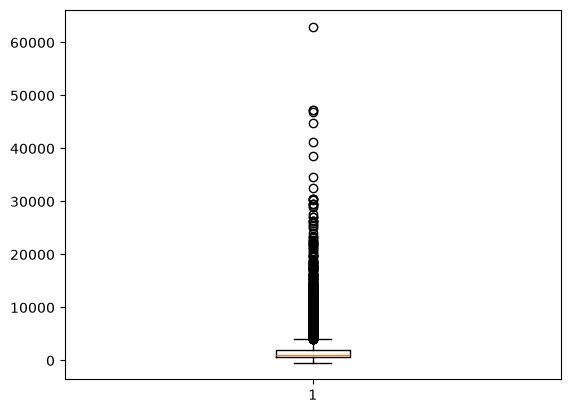

In [93]:
plt.boxplot(df['anticipatedcommission_total'])
plt.show()

In [99]:
df[df['anticipatedcommission_total']>35000]

,clientid,bkgref,Trip ID,destination,destinationcountry,destinationcountry2,category,date_of_trip_from,date_of_trip_to,year,month,bkgsource,landsalecost_total,anticipatedcommission_total,groupsize
3168,10504COM1,B16-40891,841,Aust/NZ FIT,Aust/NZ,Aust/NZ,FIT,12/17/2016,1/2/2017,2016,12,Repeat Client,241490.0,44891.0,2
4308,12-55017,B20-54006,806,Caribbean / Mexico FIT,Caribbean,Caribbean,FIT,12/18/2020,1/29/2021,2020,12,Repeat Client,630000.0,63000.0,14
6216,15044AYE2,B13-33668,650,East Africa,East Africa,East Africa,AFR,7/22/2014,8/12/2014,2014,7,Repeat Client,222676.0,41251.0,8
6584,15238DUR1,B21-54262,800,US FIT,US,US,FIT,12/19/2021,1/2/2022,2021,12,Repeat Client,312192.0,46827.0,9
7833,17-61672,B18-49047,555,Scotland Pheasants,Scotland,Scotland,WS,10/4/2019,10/10/2019,2019,10,Repeat Client,236296.0,47259.0,1
12815,46307PET1,B21-55283,808,Europe,Europe,Europe,FIT,6/10/2022,6/24/2022,2022,6,Repeat Client,182412.0,38592.0,18
13793,63131MCD1F,B15-39926,800,US FIT,US,US,FIT,7/22/2017,7/29/2017,2017,7,Repeat Client,393805.0,47256.6,1


In [100]:
df['profit_margin'] = df['anticipatedcommission_total']/df['landsalecost_total']

In [103]:
df['profit_margin'] = df['profit_margin'].replace([np.inf,-np.inf],np.nan)

In [104]:
df['profit_margin'].describe()

count    15842.000000
mean         0.153019
std          0.063168
min         -0.075829
25%          0.104990
50%          0.150000
75%          0.200000
max          2.029688
Name: profit_margin, dtype: float64

{'whiskers': [<matplotlib.lines.Line2D at 0x14da525c6e0>,
 'caps': [<matplotlib.lines.Line2D at 0x14da525c980>,
 'boxes': [<matplotlib.lines.Line2D at 0x14da525c590>],
 'medians': [<matplotlib.lines.Line2D at 0x14da525cc20>],
 'fliers': [<matplotlib.lines.Line2D at 0x14da525cd70>],
 'means': []}

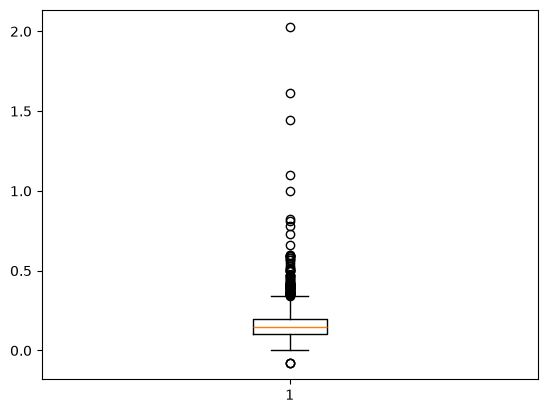

In [105]:
plt.boxplot(df['profit_margin'].dropna())

In [106]:
df[df['profit_margin']>1]

,clientid,bkgref,Trip ID,destination,destinationcountry,destinationcountry2,category,date_of_trip_from,date_of_trip_to,year,month,bkgsource,landsalecost_total,anticipatedcommission_total,groupsize,profit_margin
6100,14-58678,B16-42644,225,Seychelles Fishing,Seychelles,Seychelles,SW,1/28/2017,2/4/2017,2017,1,UK,13600.0,14960.0,2,1.100000
7616,16-61494,B18-47997,853,Canada FIT,Canada,Canada,FIT,1/20/2019,1/26/2019,2019,1,Repeat Client,622.0,900.0,1,1.446945
8079,17-62607,B17-44129,361,Martin Pescador Lodge,Chile,Chile,FO,2/8/2018,2/18/2018,2018,2,Friend,640.0,1299.0,1,2.029688
12856,47102MOR01,B21-55097,651,South Africa Photo,S. Africa,S. Africa,AFR,7/19/2021,9/5/2021,2021,7,Repeat Client,652.0,1050.0,1,1.610429


In [112]:
df[df['anticipatedcommission_total']>df['landsalecost_total']]

,clientid,bkgref,Trip ID,destination,destinationcountry,destinationcountry2,category,date_of_trip_from,date_of_trip_to,year,month,bkgsource,landsalecost_total,anticipatedcommission_total,groupsize,profit_margin
720,06836BAM2,B17-45916,651,S. Africa FIT,S. Africa,S. Africa,AFR,9/10/2018,9/27/2018,2018,9,Repeat Client,0.0,6000.00,2,NaN
947,07950HOF1,B12-29161,800,US FIT,US,US,FIT,8/6/2012,8/12/2012,2012,8,Company referral,0.0,500.00,2,NaN
1126,08-45453,B21-55144,150,Alaska Fishing,Alaska,Alaska,FW,7/11/2021,7/20/2021,2021,7,Repeat Client,0.0,3450.00,2,NaN
1154,08-45614,B17-44773,813,South America - FIT,South America,South America,FIT,2/14/2018,2/25/2018,2018,2,Repeat Client,0.0,200.00,2,NaN
1197,08-45775,B19-50805,843,British Isles,England,England,FIT,10/22/2019,10/28/2019,2019,10,Repeat Client,0.0,750.00,1,NaN
1687,09-47505,B22-56981,227,Seychelles Misc,Seychelles,Seychelles,SW,4/5/2022,4/12/2022,2022,4,UK,0.0,2108.00,1,NaN
1780,09-47833,B11-26447,813,South America - FIT,South America,South America,FIT,11/2/2011,11/20/2011,2011,11,Company referral,0.0,345.00,1,NaN
1830,09-47982,B10-23907,806,Caribbean,Caribbean,Caribbean,FIT,1/23/2011,1/29/2011,2011,1,Company referral,0.0,193.00,2,NaN
1903,09-48032,B14-35440,304,Iceland-Salmon,Iceland,Iceland,FO,7/6/2014,7/12/2014,2014,7,Repeat Client,0.0,930.75,1,NaN
3099,10-49880,B14-34025,651,S. Africa FIT,S. Africa,S. Africa,AFR,6/12/2014,7/6/2014,2014,6,Repeat Client,0.0,2805.27,3,NaN


In [122]:
df[(df['anticipatedcommission_total']>df['landsalecost_total']) & (df['landsalecost_total']==0)]

,clientid,bkgref,Trip ID,destination,destinationcountry,destinationcountry2,category,date_of_trip_from,date_of_trip_to,year,month,bkgsource,landsalecost_total,anticipatedcommission_total,groupsize,profit_margin
720,06836BAM2,B17-45916,651,S. Africa FIT,S. Africa,S. Africa,AFR,9/10/2018,9/27/2018,2018,9,Repeat Client,0.0,6000.00,2,NaN
947,07950HOF1,B12-29161,800,US FIT,US,US,FIT,8/6/2012,8/12/2012,2012,8,Company referral,0.0,500.00,2,NaN
1126,08-45453,B21-55144,150,Alaska Fishing,Alaska,Alaska,FW,7/11/2021,7/20/2021,2021,7,Repeat Client,0.0,3450.00,2,NaN
1154,08-45614,B17-44773,813,South America - FIT,South America,South America,FIT,2/14/2018,2/25/2018,2018,2,Repeat Client,0.0,200.00,2,NaN
1197,08-45775,B19-50805,843,British Isles,England,England,FIT,10/22/2019,10/28/2019,2019,10,Repeat Client,0.0,750.00,1,NaN
1687,09-47505,B22-56981,227,Seychelles Misc,Seychelles,Seychelles,SW,4/5/2022,4/12/2022,2022,4,UK,0.0,2108.00,1,NaN
1780,09-47833,B11-26447,813,South America - FIT,South America,South America,FIT,11/2/2011,11/20/2011,2011,11,Company referral,0.0,345.00,1,NaN
1830,09-47982,B10-23907,806,Caribbean,Caribbean,Caribbean,FIT,1/23/2011,1/29/2011,2011,1,Company referral,0.0,193.00,2,NaN
1903,09-48032,B14-35440,304,Iceland-Salmon,Iceland,Iceland,FO,7/6/2014,7/12/2014,2014,7,Repeat Client,0.0,930.75,1,NaN
3099,10-49880,B14-34025,651,S. Africa FIT,S. Africa,S. Africa,AFR,6/12/2014,7/6/2014,2014,6,Repeat Client,0.0,2805.27,3,NaN


In [124]:
df = df.drop(df[(df['anticipatedcommission_total']>df['landsalecost_total']) & (df['landsalecost_total']==0)].index)

In [125]:
df.describe()

,Trip ID,year,month,landsalecost_total,anticipatedcommission_total,groupsize,profit_margin
count,16632.000000,16632.000000,16632.000000,16632.000000,16632.000000,16632.000000,15842.000000
mean,499.274291,2016.674122,6.053632,11981.828185,1710.794128,1.944024,0.153019
std,265.947645,3.156337,3.085148,18510.733933,2477.038548,1.564536,0.063168
min,101.000000,2010.000000,1.000000,0.000000,-400.000000,1.000000,-0.075829
25%,241.000000,2014.000000,4.000000,4066.500000,590.000000,1.000000,0.104990
50%,380.000000,2017.000000,6.000000,7200.000000,1071.030000,2.000000,0.150000
75%,806.000000,2019.000000,8.000000,13639.500000,2000.000000,2.000000,0.200000
max,890.000000,2022.000000,12.000000,630000.000000,63000.000000,18.000000,2.029688


In [127]:
df['anticipatedcommission_total'].corr(df['landsalecost_total'])

np.float64(0.8875005845072219)

In [134]:
df['bkgsource'].value_counts()

bkgsource
Repeat Client        9189
UK                   2116
Company referral     1942
Friend               1869
Agent/Outfitter       728
Web/Internet/Mail     636
Organizations          50
Frontiers, Ltd.        37
Unknown                24
Magazine               23
Trade Shows            13
Internet Chat           5
Name: count, dtype: int64

In [135]:
df.info()

<class 'pandas.DataFrame'>
Index: 16632 entries, 0 to 16680
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   clientid                     16632 non-null  str    
 1   bkgref                       16632 non-null  str    
 2   Trip ID                      16632 non-null  int64  
 3   destination                  16632 non-null  str    
 4   destinationcountry           16632 non-null  str    
 5   destinationcountry2          16632 non-null  str    
 6   category                     16632 non-null  str    
 7   date_of_trip_from            16632 non-null  str    
 8   date_of_trip_to              16632 non-null  str    
 9   year                         16632 non-null  int64  
 10  month                        16632 non-null  int64  
 11  bkgsource                    16632 non-null  str    
 12  landsalecost_total           16632 non-null  float64
 13  anticipatedcommission_total  166

#### Export current dataframe to csv file for group to use

In [136]:
df.to_csv("cleanTravelData.csv",index=False)

### Data Visualization